# Projection

> Part of *PHYS 0241: Biomedical Imaging* (Prof. Michael E. Durst, Middlebury College). The [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch09/ch09-01.html) shows the rendered version together with the pre-rendered animations (course password required).
>
> **Start here:** no setup is needed for this notebook. In Google Colab, choose **File > Save a copy in Drive** to keep your changes.
>
> *Provided for academic use in PHYS 0241; please do not repost or redistribute ([terms of use](https://github.com/durstme/textbook-biomedicalimaging-notebooks/blob/main/LICENSE.md)).*

## Import libraries

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

## Define parameters

In [23]:

# --- 1. PARAMETERS (Hardcoded, replacing sliders) ---
# Image dimensions
dims = 64
half_dims = dims / 2

# Selection variables (Modify these to change the output)
# 0: Disk, 1: Diamond, 2: Box, 3: Diagonal, 4: Cross
shape_selection = 0 

# "Manipulate" variables
rho_target = 10.0            # Distance from center (rho)
theta_deg = 45.0             # Angle in degrees
theta = np.radians(theta_deg)

# --- 2. CREATE OBJECTS (Equivalent to *Choose Object*) ---
# Create a coordinate grid centered at (0,0)
y, x = np.ogrid[-dims//2:dims//2, -dims//2:dims//2]

# 1. Disk (DiskMatrix)
disk = (x**2 + y**2 <= 16**2).astype(float)

# 2. Diamond (DiamondMatrix - Manhattan distance)
diamond = (np.abs(x) + np.abs(y) <= 16*np.sqrt(2)).astype(float)

# 3. Box (BoxMatrix - Chebyshev distance)
box = ((np.abs(x) <= 16) & (np.abs(y) <= 16)).astype(float)

# 4. Diagonal (SparseArray Band)
# Creating a thick diagonal line to simulate the band effect visible in 64x64
diagonal = np.eye(dims)
# Dilate slightly to make it visible like the Mathematica output
diagonal = np.clip(diagonal + np.eye(dims, k=1) + np.eye(dims, k=-1), 0, 1)

# 5. Cross (CrossMatrix)
cross = ((np.abs(x) <= 4) | (np.abs(y) <= 4)).astype(float) # Thinner arms for cross
# Or strictly matching BoxMatrix dimensions for the cross arms:
cross_thick = (((np.abs(x) <= 16) & (np.abs(y) <= 16/4)) | 
               ((np.abs(x) <= 16/4) & (np.abs(y) <= 16))).astype(float)

object_list = [disk, diamond, box, diagonal, cross_thick]
g1 = object_list[shape_selection]

# --- 3. CALCULATE TOTAL PROJECTION (Equivalent to g2/totalproj) ---
# We need to calculate the sum of the projection for ALL rho values 
# to generate the plot on the right.

# Range of rho values (diagonal of the image)
max_rho = int(np.ceil(dims * np.sqrt(2) / 2))
rho_values = np.arange(-max_rho, max_rho + 1)
total_proj_values = []

# Range for 's' (parameter along the line)
s_range = np.arange(-dims, dims + 1)

# Pre-calculate trig for the fixed theta
cos_t = np.cos(theta)
sin_t = np.sin(theta)

for r in rho_values:
    # Parametric line equation:
    # x = rho * cos(theta) - s * sin(theta) + center_offset
    # y = rho * sin(theta) + s * cos(theta) + center_offset
    
    x_coords = r * cos_t - s_range * sin_t + half_dims
    y_coords = r * sin_t + s_range * cos_t + half_dims
    
    # Nearest neighbor interpolation logic
    x_idx = np.round(x_coords).astype(int)
    y_idx = np.round(y_coords).astype(int)
    
    # Filter valid indices within image bounds
    valid_mask = (x_idx >= 0) & (x_idx < dims) & (y_idx >= 0) & (y_idx < dims)
    
    # Sum pixel values for this rho
    if np.any(valid_mask):
        val_sum = np.sum(g1[y_idx[valid_mask], x_idx[valid_mask]])
    else:
        val_sum = 0
    total_proj_values.append(val_sum)

total_proj_values = np.array(total_proj_values)



# --- 4. CALCULATE CURRENT SELECTION (Equivalent to projection function) ---
# Now calculate the specific line profile for the chosen 'rho_target'

x_line = rho_target * cos_t - s_range * sin_t + half_dims
y_line = rho_target * sin_t + s_range * cos_t + half_dims

# Nearest neighbor sampling for the line profile
x_idx_line = np.round(x_line).astype(int)
y_idx_line = np.round(y_line).astype(int)
valid_line = (x_idx_line >= 0) & (x_idx_line < dims) & (y_idx_line >= 0) & (y_idx_line < dims)

# Extract values
line_profile = np.zeros_like(s_range, dtype=float)
# Note: numpy uses [row, col] -> [y, x]
line_profile[valid_line] = g1[y_idx_line[valid_line], x_idx_line[valid_line]]

# Filter arrays for plotting the Red Line on the image
# (Only keep points that are actually inside the image for the visual overlay)
x_overlay = x_line[valid_line]
y_overlay = y_line[valid_line]

# Find the projection value closest to our chosen rho
current_proj_val = total_proj_values[np.abs(rho_values - rho_target).argmin()]


## Plot

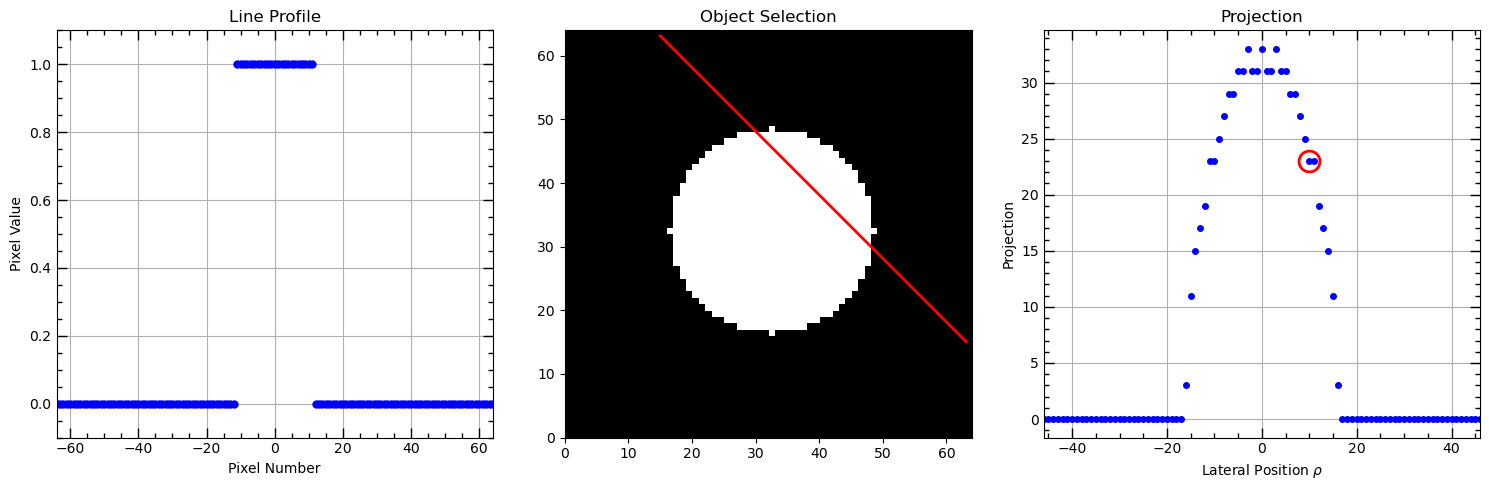

In [7]:
# --- 5. VISUALIZATION (Equivalent to Manipulate GraphicsRow) ---
fig1, axes1 = plt.subplots(1, 3, figsize=(15, 5))

# PLOT 1: Line Profile
# Corresponds to: ListPlot[Transpose[{projectionxvalues... projection...}]]
axes1[0].plot(s_range, line_profile, 'b.', markersize=10)
axes1[0].set_xlim(-dims, dims)
axes1[0].set_ylim(-0.1, 1.1)
axes1[0].set_xlabel("Pixel Number")
axes1[0].set_ylabel("Pixel Value")
axes1[0].set_title("Line Profile")
axes1[0].grid(True)
axes1[0].minorticks_on()
axes1[0].tick_params(which='both',direction="in",width=1)
axes1[0].tick_params(which='major',length=7)
axes1[0].tick_params(which='minor',length=3.5)
axes1[0].xaxis.set_ticks_position('both')
axes1[0].yaxis.set_ticks_position('both')

# PLOT 2: Image with Line
# Corresponds to: Show[g1, Graphics[{Red, Line...}]]
# origin='lower' puts (0,0) at bottom-left to match standard math/Mathematica coords
axes1[1].imshow(g1, cmap='gray', origin='lower', extent=[0, dims, 0, dims], vmin=0, vmax=1)
if len(x_overlay) > 1:
    axes1[1].plot(x_overlay, y_overlay, 'r-', linewidth=2)
axes1[1].set_title("Object Selection")
axes1[1].set_xlim(0, dims)
axes1[1].set_ylim(0, dims)


# PLOT 3: Projection (Radon transform slice)
# Corresponds to: Show[g2, Graphics[{Red, Circle...}]]
axes1[2].plot(rho_values, total_proj_values, 'b.', markersize=8)
# Highlight: Use a plot marker (not a Patch) to ensure it stays circular
axes1[2].plot(rho_target, current_proj_val, 
              marker='o',          # Circle shape
              markersize=15,       # Large size
              markerfacecolor='none', # Transparent inside
              markeredgecolor='red',  # Red outline
              markeredgewidth=2)
axes1[2].set_xlim(-max_rho, max_rho)
axes1[2].minorticks_on()
axes1[2].tick_params(which='both',direction="in",width=1)
axes1[2].tick_params(which='major',length=7)
axes1[2].tick_params(which='minor',length=3.5)
axes1[2].xaxis.set_ticks_position('both')
axes1[2].yaxis.set_ticks_position('both')
axes1[2].set_xlabel(r"Lateral Position $\rho$")
axes1[2].set_ylabel("Projection")
axes1[2].set_title("Projection")
axes1[2].grid(True)

plt.tight_layout()
plt.show()

## Use ipywidgets to interactively change shape and update the plot

In [ ]:
# --- 1. SETUP AND IMPORTS ---
# Run this cell in a Jupyter Notebook to see the interactive output.
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

# --- 2. PRE-CALCULATE SHAPES ---
# We generate the shapes once to save computation time during interaction.
dims2 = 64
half_dims2 = dims2 / 2
y2, x2 = np.ogrid[-dims2//2:dims2//2, -dims2//2:dims2//2]

# 1. Disk
disk2 = (x2**2 + y2**2 <= 16**2).astype(float)
# 2. Diamond
diamond2 = (np.abs(x2) + np.abs(y2) <= 16*np.sqrt(2)).astype(float)
# 3. Box
box2 = ((np.abs(x2) <= 16) & (np.abs(y2) <= 16)).astype(float)
# 4. Diagonal
diag_mat = np.eye(dims2)
diagonal2 = np.clip(diag_mat + np.eye(dims2, k=1) + np.eye(dims2, k=-1), 0, 1)
# 5. Cross
cross_thick2 = (((np.abs(x2) <= 16) & (np.abs(y2) <= 16/4)) | 
               ((np.abs(x2) <= 16/4) & (np.abs(y2) <= 16))).astype(float)

object_list2 = [disk2, diamond2, box2, diagonal2, cross_thick2]
shape_names = ['Disk', 'Diamond', 'Box', 'Diagonal', 'Cross']

# --- 3. DEFINING THE UPDATE FUNCTION ---
def update_plot(shape_index, theta_deg, rho_target):
    
    # Select Object
    g1 = object_list2[shape_index]
    theta = np.radians(theta_deg)
    
    # --- CALCULATE TOTAL PROJECTION (Right Plot) ---
    max_rho = int(np.ceil(dims2 * np.sqrt(2) / 2))
    rho_values = np.arange(-max_rho, max_rho + 1)
    total_proj_values = []
    s_range = np.arange(-dims2, dims2 + 1)

    cos_t = np.cos(theta)
    sin_t = np.sin(theta)

    # Loop to calculate Radon transform slice (projection)
    for r in rho_values:
        x_coords = r * cos_t - s_range * sin_t + half_dims2
        y_coords = r * sin_t + s_range * cos_t + half_dims2
        
        x_idx = np.round(x_coords).astype(int)
        y_idx = np.round(y_coords).astype(int)
        
        valid_mask = (x_idx >= 0) & (x_idx < dims2) & (y_idx >= 0) & (y_idx < dims2)
        
        if np.any(valid_mask):
            val_sum = np.sum(g1[y_idx[valid_mask], x_idx[valid_mask]])
        else:
            val_sum = 0
        total_proj_values.append(val_sum)

    total_proj_values = np.array(total_proj_values)

    # --- CALCULATE CURRENT SELECTION (Left/Middle Plots) ---
    x_line = rho_target * cos_t - s_range * sin_t + half_dims2
    y_line = rho_target * sin_t + s_range * cos_t + half_dims2

    x_idx_line = np.round(x_line).astype(int)
    y_idx_line = np.round(y_line).astype(int)
    valid_line = (x_idx_line >= 0) & (x_idx_line < dims2) & (y_idx_line >= 0) & (y_idx_line < dims2)

    line_profile = np.zeros_like(s_range, dtype=float)
    line_profile[valid_line] = g1[y_idx_line[valid_line], x_idx_line[valid_line]]

    x_overlay = x_line[valid_line]
    y_overlay = y_line[valid_line]

    # Find closest projection value for the red circle
    current_proj_val = total_proj_values[np.abs(rho_values - rho_target).argmin()]

    # --- VISUALIZATION ---
    # Using fig2 and axes2 as requested
    fig2, axes2 = plt.subplots(1, 3, figsize=(15, 5))

    # PLOT 1: Line Profile
    axes2[0].plot(s_range, line_profile, 'b.', markersize=10)
    axes2[0].set_xlim(-dims2, dims2)
    axes2[0].set_ylim(-0.1, 1.1)
    axes2[0].set_xlabel("Pixel Number")
    axes2[0].set_ylabel("Pixel Value")
    axes2[0].set_title("Line Profile")
    axes2[0].grid(True)
    
    # Custom ticks settings
    axes2[0].minorticks_on()
    axes2[0].tick_params(which='both', direction="in", width=1)
    axes2[0].tick_params(which='major', length=7)
    axes2[0].tick_params(which='minor', length=3.5)
    axes2[0].xaxis.set_ticks_position('both')
    axes2[0].yaxis.set_ticks_position('both')

    # PLOT 2: Image with Line
    axes2[1].imshow(g1, cmap='gray', origin='lower', extent=[0, dims2, 0, dims2], vmin=0, vmax=1)
    if len(x_overlay) > 1:
        axes2[1].plot(x_overlay, y_overlay, 'r-', linewidth=2)
    axes2[1].set_title(f"Object Selection: {shape_names[shape_index]}")
    axes2[1].set_xlim(0, dims2)
    axes2[1].set_ylim(0, dims2)

    # PLOT 3: Projection
    axes2[2].plot(rho_values, total_proj_values, 'b.', markersize=8)
    axes2[2].plot(rho_target, current_proj_val, 
                  marker='o',          
                  markersize=15,       
                  markerfacecolor='none', 
                  markeredgecolor='red',  
                  markeredgewidth=2)
    
    axes2[2].set_xlim(-max_rho, max_rho)
    axes2[2].set_xlabel(r"Lateral Position $\rho$")
    axes2[2].set_ylabel("Projection")
    axes2[2].set_title("Projection")
    axes2[2].grid(True)
    
    # Custom ticks settings
    axes2[2].minorticks_on()
    axes2[2].tick_params(which='both', direction="in", width=1)
    axes2[2].tick_params(which='major', length=7)
    axes2[2].tick_params(which='minor', length=3.5)
    axes2[2].xaxis.set_ticks_position('both')
    axes2[2].yaxis.set_ticks_position('both')

    plt.tight_layout()
    plt.show()

# --- 4. CREATE WIDGETS ---
w_shape = widgets.Dropdown(
    options=[('Disk', 0), ('Diamond', 1), ('Box', 2), ('Diagonal', 3), ('Cross', 4)],
    value=0,
    description='Shape:'
)

w_rho = widgets.FloatSlider(
    value=10.0,
    min=-45.0,
    max=45.0,
    step=1.0,
    description='Rho:',
    continuous_update=False  # Set to True for real-time (might be laggy)
)

w_theta = widgets.FloatSlider(
    value=45.0,
    min=0.0,
    max=90.0,
    step=1.0,
    description='Theta (deg):',
    continuous_update=False
)

# --- 5. RUN INTERACTIVE PLOT ---
interactive_plot = widgets.interactive(update_plot, 
                                       shape_index=w_shape, 
                                       theta_deg=w_theta, 
                                       rho_target=w_rho)
display(interactive_plot)

### Display animation with javascript from standalone html
[Link to animation](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch09/ch09-01_animation.html)

*Animation.* The pre-rendered animation for this section is shown on the [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch09/ch09-01.html) (direct link: [ch09-01_animation.html](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch09/ch09-01_animation.html)). It is not embedded here because Colab cannot load files from the textbook site; running the code above produces the live version.